# 2.0 Operational congestion proxy on 2022: labels, feasibility and design checks
**Purpose.** Build the final label on the 2022 design year and check, before the design freeze, that it can carry the experiment. Congestion is the concept of interest, but the URB data hold no independent congestion measure, so the label is an operational proxy: the onset of **persistent unusually high district occupancy**.

**Inputs.** `data/processed/district-series-2022.parquet` and `panel.parquet` (built by `madrid_congestion.districts`), and the 2022 panel readings for the composition audit. No 2023 or 2024 data are read.

The superseded curve-based critical-point label is kept in `archive/2.0a-anh-critical-point-attempt-2022.ipynb`.

## 1. Setup

In [15]:
from datetime import datetime

import matplotlib.pyplot as plt
import polars as pl

from madrid_congestion.config import (
    CALM_SLOTS,
    FIGURES_DIR,
    HIGH_OCC_QUANTILE,
    HORIZONS,
    MIN_EPISODE_SLOTS,
    PANEL_YEAR,
    PROCESSED_DATA_DIR,
    SLOT,
    SUPPORT_SHARE,
    WEEKEND_FROM,
)
from madrid_congestion.districts import PANEL_PATH, VALID_READING, months_of, slot_rows

assert MIN_EPISODE_SLOTS == 2  # the onset rule in section 4 checks one following slot
series = pl.read_parquet(PROCESSED_DATA_DIR / f"district-series-{PANEL_YEAR}.parquet")
panel = pl.read_parquet(PANEL_PATH).select("id", "distrito")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
print(f"{series.height:,} district slots, {series['distrito'].n_unique()} districts, {panel.height:,} panel sensors")

ImportError: cannot import name 'WEEKEND_FROM' from 'madrid_congestion.config' (E:\Madrid-traffic-ageing_Advanced project\madrid-congestion\madrid_congestion\config.py)

## 2. District support
**Purpose.** A district's percentile threshold describes it only if most of its year is observed. **Method.** A district is studied only if at least half of its 2022 slots are valid. This rule was set during the 2022 design stage, after the coverage problem of district 19 was seen (its panel has exactly 30 sensors, and the valid-slot rule needs all 30).

In [ ]:
support = series.group_by("distrito").agg(
    valid_share=pl.col("valid_slot").mean(),
    valid_share_07_19=pl.col("valid_slot").filter(pl.col("slot_start").dt.hour().is_between(7, 19)).mean(),
).sort("distrito")
studied = support.filter(pl.col("valid_share") >= SUPPORT_SHARE)["distrito"]
print("studied:", studied.len(), "| not studied:", support.filter(pl.col("valid_share") < SUPPORT_SHARE)["distrito"].to_list())
support

studied: 19 | not studied: [19]


distrito,valid_share,valid_share_07_19
i64,f64,f64
1,0.86335,0.872076
2,0.835745,0.871338
3,0.943593,0.968072
4,0.95798,0.971444
5,0.928178,0.950474
6,0.947932,0.95843
7,0.95347,0.967071
8,0.889584,0.961749
9,0.851846,0.971812


**Result.** District 19 has 11.9% valid slots (2.9% between 07:00 and 19:59); every other district has at least 84%, so the exact cut-off does not matter. **Implication.** 19 districts are studied.

## 3. High-occupancy thresholds and flow references
**Method.** On the valid 2022 slots of each studied district: the high-occupancy threshold is the 95th percentile of district occupancy, and the flow reference is the 95th percentile of district flow (polars default quantile, nearest rank). Both are fixed here and used unchanged for 2023 and 2024. The threshold is a pragmatic operational definition, not a capacity; the flow reference only puts district flows on a common scale.

In [ ]:
# Every 2022 slot start on a regular 15-minute grid of local clock time; slots missing from the series
# (clock-change rows, the year's last slot) count as invalid, so no value is ever filled in.
grid = pl.datetime_range(datetime(PANEL_YEAR, 1, 1), datetime(PANEL_YEAR, 12, 31, 23, 45), "15m", eager=True).alias("slot_start")
full = (
    studied.to_frame().join(grid.to_frame(), how="cross")
    .join(series.select("distrito", "slot_start", "occupancy", "flow", "valid_slot"), on=["distrito", "slot_start"], how="left")
    .with_columns(pl.col("valid_slot").fill_null(False))
    .sort("distrito", "slot_start")
)
references = full.filter(pl.col("valid_slot")).group_by("distrito").agg(
    valid_slots=pl.len(),
    threshold=pl.col("occupancy").quantile(HIGH_OCC_QUANTILE),
    flow_reference=pl.col("flow").quantile(HIGH_OCC_QUANTILE),
).sort("distrito")
references

distrito,valid_slots,threshold,flow_reference
i64,u32,f64,f64
1,30244,18.542553,687.029703
2,29277,12.243902,875.6625
3,33055,12.266667,876.684211
4,33559,13.64,977.047244
5,32515,13.80814,845.034682
6,33207,9.537879,731.080882
7,33401,12.131313,972.342593
8,31163,9.814035,455.73064
9,29841,12.587302,617.76378


## 4. Labels: high-occupancy slots, episodes, onsets and targets
**Method.** A *high-occupancy slot* is a valid slot at or above the threshold. A *persistent high-occupancy episode* is at least two such slots in a row (30 minutes). The *onset* is its first slot; the slot before must be valid and below the threshold. An origin *t* is *calm* if none of *t*−3 … *t* is a high-occupancy slot. The 30-minute (60-minute) target is positive if an onset starts in *t*+1 … *t*+2 (*t*+4). An origin is *usable* if every slot from *t*−3 to *t*+*H*+1 is valid (history, target window and the slot that confirms an episode starting at the window's end).

In [ ]:
def later(column: str, k: int) -> pl.Expr:
    # The value k slots later (k > 0) or earlier (k < 0) in the same district; outside the year it is null.
    return pl.col(column).shift(-k).over("distrito")


labels = full.join(references.select("distrito", "threshold", "flow_reference"), on="distrito").with_columns(
    high=pl.col("valid_slot") & (pl.col("occupancy") >= pl.col("threshold")),
    relative_occupancy=pl.col("occupancy") / pl.col("threshold"),
    relative_flow=pl.col("flow") / pl.col("flow_reference"),
)
labels = labels.with_columns(
    # onset: this slot and the next are high, and the slot before is valid and below the threshold
    onset=pl.col("high") & later("high", 1).fill_null(False) & later("valid_slot", -1).fill_null(False) & ~later("high", -1).fill_null(True),
    calm=pl.all_horizontal([~later("high", -k).fill_null(True) for k in range(CALM_SLOTS)]),
    history_valid=pl.all_horizontal([later("valid_slot", -k).fill_null(False) for k in range(CALM_SLOTS)]),
)
for minutes, H in HORIZONS.items():
    labels = labels.with_columns(
        pl.any_horizontal([later("onset", k).fill_null(False) for k in range(1, H + 1)]).alias(f"target_{minutes}"),
        (pl.col("calm") & pl.col("history_valid")
         & pl.all_horizontal([later("valid_slot", k).fill_null(False) for k in range(1, H + 2)])).alias(f"usable_{minutes}"),
    )

# Runs of consecutive high-occupancy slots; an episode is a run of at least MIN_EPISODE_SLOTS
runs = (
    labels.with_columns(run=(pl.col("high") & ~later("high", -1).fill_null(False)).cast(pl.Int32).cum_sum().over("distrito"))
    .filter(pl.col("high"))
    .group_by("distrito", "run")
    .agg(start=pl.col("slot_start").min(), end=pl.col("slot_start").max(), slots=pl.len(), onset=pl.col("onset").any())
)
episodes = runs.filter(pl.col("slots") >= MIN_EPISODE_SLOTS).sort("distrito", "start").with_columns(
    gap_slots=(pl.col("start") - pl.col("end").shift(1).over("distrito")).dt.total_minutes() // 15 - 1,
)
print(f"single high slots: {runs.filter(pl.col('slots') == 1).height:,} | episodes: {episodes.height:,} "
      f"| episodes without an onset (slot before invalid or before the year): {episodes.filter(~pl.col('onset')).height}")

single high slots: 3,195 | episodes: 5,876 | episodes without an onset (slot before invalid or before the year): 410


## 5. Feasibility of the label (paper Table 3.3)
**Purpose.** Check that the proxy gives enough positive cases for the experiment. This check can stop the design; it cannot change the percentile.

In [ ]:
counts = [
    labels.group_by("distrito").agg(
        pl.col(f"usable_{m}").sum().alias(f"origins_{m}"),
        (pl.col(f"usable_{m}") & pl.col(f"target_{m}")).sum().alias(f"positive_{m}"),
    )
    for m in HORIZONS
]
feasibility = (
    references.select("distrito", "valid_slots", pl.col("threshold").round(1))
    .join(labels.group_by("distrito").agg(high_slots=pl.col("high").sum(), onsets=pl.col("onset").sum()), on="distrito")
    .join(episodes.group_by("distrito").agg(episodes=pl.len(), median_slots=pl.col("slots").median()), on="distrito")
    .join(counts[0], on="distrito").join(counts[1], on="distrito")
    .with_columns(
        base_rate_30=(pl.col("positive_30") / pl.col("origins_30") * 100).round(2),
        base_rate_60=(pl.col("positive_60") / pl.col("origins_60") * 100).round(2),
    )
    .sort("distrito")
)
display(feasibility)
totals = feasibility.select(pl.col("valid_slots", "high_slots", "episodes", "onsets", "origins_30", "positive_30", "origins_60", "positive_60").sum())
totals.with_columns(
    base_rate_30=(pl.col("positive_30") / pl.col("origins_30") * 100).round(2),
    base_rate_60=(pl.col("positive_60") / pl.col("origins_60") * 100).round(2),
)

distrito,valid_slots,threshold,high_slots,onsets,episodes,median_slots,origins_30,positive_30,origins_60,positive_60,base_rate_30,base_rate_60
i64,u32,f64,u32,u32,u32,f64,u32,u32,u32,u32,f64,f64
1,30244,18.5,1513,189,256,4.0,21668,213,20357,403,0.98,1.98
2,29277,12.2,1465,186,231,5.0,19897,291,18437,560,1.46,3.04
3,33055,12.3,1654,234,243,6.0,25996,325,24735,554,1.25,2.24
4,33559,13.6,1679,311,322,4.0,27318,503,26283,969,1.84,3.69
5,32515,13.8,1627,285,294,5.0,25924,517,24673,1001,1.99,4.06
6,33207,9.5,1661,281,294,5.0,26980,482,25909,965,1.79,3.72
7,33401,12.1,1672,305,323,3.0,27159,453,26130,914,1.67,3.5
8,31163,9.8,1559,314,342,4.0,23039,491,21855,950,2.13,4.35
9,29841,12.6,1493,276,291,4.0,22174,445,21025,871,2.01,4.14


valid_slots,high_slots,episodes,onsets,origins_30,positive_30,origins_60,positive_60,base_rate_30,base_rate_60
u32,u32,u32,u32,u32,u32,u32,u32,f64,f64
613362,30695,5876,5466,475434,8080,453544,15510,1.7,3.42


In [ ]:
# Table 3.3 as Markdown, ready to paste into the report (same columns, rounding and order as the paper)
HEADER = ["District", "Threshold (% occupancy)", "Episodes", "Onsets",
          "Usable origins, 30 min", "Positive, 30 min", "Base rate, 30 min",
          "Usable origins, 60 min", "Positive, 60 min", "Base rate, 60 min"]
lines = ["| " + " | ".join(HEADER) + " |", "|" + "---|" * len(HEADER)]
for r in feasibility.iter_rows(named=True):
    lines.append(
        f"| {r['distrito']} | {r['threshold']:.1f} | {r['episodes']:,} | {r['onsets']:,} "
        f"| {r['origins_30']:,} | {r['positive_30']:,} | {r['base_rate_30']:.2f}% "
        f"| {r['origins_60']:,} | {r['positive_60']:,} | {r['base_rate_60']:.2f}% |"
    )
t = totals.row(0, named=True)  # base rates of the totals row: pooled positives / pooled origins
lines.append(
    f"| **All {feasibility.height}** | | **{t['episodes']:,}** | **{t['onsets']:,}** "
    f"| **{t['origins_30']:,}** | **{t['positive_30']:,}** | **{t['positive_30'] / t['origins_30']:.2%}** "
    f"| **{t['origins_60']:,}** | **{t['positive_60']:,}** | **{t['positive_60'] / t['origins_60']:.2%}** |"
)
print("\n".join(lines))

| District | Threshold (% occupancy) | Episodes | Onsets | Usable origins, 30 min | Positive, 30 min | Base rate, 30 min | Usable origins, 60 min | Positive, 60 min | Base rate, 60 min |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 18.5 | 256 | 189 | 21,668 | 213 | 0.98% | 20,357 | 403 | 1.98% |
| 2 | 12.2 | 231 | 186 | 19,897 | 291 | 1.46% | 18,437 | 560 | 3.04% |
| 3 | 12.3 | 243 | 234 | 25,996 | 325 | 1.25% | 24,735 | 554 | 2.24% |
| 4 | 13.6 | 322 | 311 | 27,318 | 503 | 1.84% | 26,283 | 969 | 3.69% |
| 5 | 13.8 | 294 | 285 | 25,924 | 517 | 1.99% | 24,673 | 1,001 | 4.06% |
| 6 | 9.5 | 294 | 281 | 26,980 | 482 | 1.79% | 25,909 | 965 | 3.72% |
| 7 | 12.1 | 323 | 305 | 27,159 | 453 | 1.67% | 26,130 | 914 | 3.50% |
| 8 | 9.8 | 342 | 314 | 23,039 | 491 | 2.13% | 21,855 | 950 | 4.35% |
| 9 | 12.6 | 291 | 276 | 22,174 | 445 | 2.01% | 21,025 | 871 | 4.14% |
| 10 | 10.6 | 350 | 320 | 26,237 | 442 | 1.68% | 25,350 | 869 | 3.43% |
| 11 | 11.0 | 323 | 293 | 26,235 | 424 | 1.62% | 25,344 | 83

In [ ]:
slots = episodes["slots"]
print("episode length in slots: quartiles", slots.quantile(0.25), slots.median(), slots.quantile(0.75),
      "| 90th percentile", slots.quantile(0.9), "| longest", slots.max())
print(f"exactly 30 min: {(slots == 2).mean():.1%} | longer than 2 h: {(slots > 8).mean():.1%}")
gaps = episodes.filter(pl.col("gap_slots").is_not_null())
print(f"episodes starting less than one hour after the previous one ended: {gaps.filter(pl.col('gap_slots') < CALM_SLOTS).height} of {gaps.height}")
for minutes, H in HORIZONS.items():
    reached = labels.with_columns(pl.any_horizontal([later(f"usable_{minutes}", -k).fill_null(False) for k in range(1, H + 1)]).alias("reached"))
    print(f"{minutes} min: onsets with at least one usable calm origin before them: {reached.filter(pl.col('onset'))['reached'].sum():,}")
onset_hours = labels.filter(pl.col("onset")).group_by(hour=pl.col("slot_start").dt.hour()).agg(onsets=pl.len()).sort("hour")
print(f"share of onsets starting 08:00-08:59: {onset_hours.filter(pl.col('hour') == 8)['onsets'].item() / onset_hours['onsets'].sum():.1%}")
print("onsets per starting hour:", dict(onset_hours.iter_rows()))

episode length in slots: quartiles 2.0 4.0 6.0 | 90th percentile 8.0 | longest 28
exactly 30 min: 25.3% | longer than 2 h: 9.0%
episodes starting less than one hour after the previous one ended: 711 of 5857
30 min: onsets with at least one usable calm origin before them: 4,153
60 min: onsets with at least one usable calm origin before them: 4,575
share of onsets starting 08:00-08:59: 35.2%
onsets per starting hour: {7: 425, 8: 1926, 9: 38, 10: 55, 11: 130, 12: 102, 13: 139, 14: 624, 15: 57, 16: 188, 17: 627, 18: 987, 19: 144, 20: 20, 21: 4}


**Result.** The 19 districts have 5,876 episodes and 5,466 onsets in 2022, at least 186 per district. Usable calm origins: 475,434 at 30 minutes with 8,080 positives (base rate 1.70%) and 453,544 at 60 minutes with 15,510 positives (3.42%). Episodes last one hour in the median; a quarter last exactly 30 minutes. Onsets cluster in the morning and evening peaks (35% start between 08:00 and 08:59). **Implication.** The label is usable and is accepted unchanged; the calendar baseline will be a demanding reference.

## 6. High-flow origins for the mechanism diagnostics
**Method.** A high-flow origin has relative flow ≥ 1 at *t*. This is the only definition; the diagnostics are reported as too sparse at a horizon if the 2024 test year has fewer than 100 high-flow origins followed by an onset.

In [ ]:
for minutes in HORIZONS:
    usable = labels.filter(pl.col(f"usable_{minutes}"))
    high_flow = usable.filter(pl.col("relative_flow") >= 1)
    print(f"{minutes} min: high-flow usable calm origins {high_flow.height:,}, followed by an onset {high_flow[f'target_{minutes}'].sum():,} "
          f"| base rate {high_flow[f'target_{minutes}'].mean():.3f} vs {usable.filter(pl.col('relative_flow') < 1)[f'target_{minutes}'].mean():.3f} for other origins")

30 min: high-flow usable calm origins 6,954, followed by an onset 2,192 | base rate 0.315 vs 0.013 for other origins
60 min: high-flow usable calm origins 6,814, followed by an onset 2,571 | base rate 0.377 vs 0.029 for other origins


**Result.** 2,192 (30 min) and 2,571 (60 min) high-flow origins are followed by an onset, far above 100. **Implication.** Diagnostic 1 and 2 should have enough cases; high current flow is itself a strong signal (base rate about 0.32 against 0.01).

## 7. Calendar baseline
**Purpose.** The calendar baseline shows what the timetable alone predicts, so that a model must do better than recurrent traffic to add anything. **Method.** For each studied district, day type (weekday or weekend; Saturday and Sunday are the weekend, and a public holiday counts as its weekday) and 15-minute slot of day, the share of 2022 usable calm origins with a positive target, separately for 30 and 60 minutes. The share is the warning score, used unchanged in 2023 and 2024. Seven separate weekdays are not used: a district × weekday × slot cell holds only about 52 days a year, too few for an event with a base rate of 1.7–3.4%. A cell without any usable calm origin in 2022 has no share and takes the share of its district and day type over all slots. No smoothing and no other grouping is used.

In [ ]:
calendar_keys = [
    (pl.col("slot_start").dt.weekday() >= WEEKEND_FROM).alias("weekend"),
    (pl.col("slot_start").dt.hour().cast(pl.Int32) * 4 + pl.col("slot_start").dt.minute() // 15).alias("slot_of_day"),
]
# Every district x day type x slot of day, so that cells without a usable calm origin are kept and visible
cells = studied.to_frame().join(pl.DataFrame({"weekend": [False, True]}), how="cross").join(
    pl.int_range(0, 96, dtype=pl.Int32, eager=True).alias("slot_of_day").to_frame(), how="cross")
calendar = []
for minutes in HORIZONS:
    usable = labels.filter(pl.col(f"usable_{minutes}")).with_columns(calendar_keys)
    by_cell = usable.group_by("distrito", "weekend", "slot_of_day").agg(origins=pl.len(), positives=pl.col(f"target_{minutes}").sum())
    by_day_type = usable.group_by("distrito", "weekend").agg(day_type_rate=pl.col(f"target_{minutes}").mean())
    calendar.append(
        cells.join(by_cell, on=["distrito", "weekend", "slot_of_day"], how="left")
        .join(by_day_type, on=["distrito", "weekend"])
        .with_columns(pl.col("origins", "positives").fill_null(0), horizon=pl.lit(minutes))
        # an empty cell (no usable calm origin in 2022) takes the share of its district and day type over all slots
        .with_columns(calendar_rate=pl.when(pl.col("origins") > 0).then(pl.col("positives") / pl.col("origins")).otherwise(pl.col("day_type_rate")))
    )
calendar = pl.concat(calendar)
calendar.group_by("horizon", "weekend").agg(
    cells=pl.len(),
    empty_cells=(pl.col("origins") == 0).sum(),
    median_origins=pl.col("origins").median(),
    cells_with_a_positive=(pl.col("positives") > 0).sum(),
    max_rate=pl.col("calendar_rate").max().round(3),
).sort("horizon", "weekend")

horizon,weekend,cells,empty_cells,median_origins,cells_with_a_positive,max_rate
i32,bool,u32,u32,f64,u32,f64
30,false,1824,30,202.0,535,0.699
30,true,1824,79,92.0,53,0.038
60,false,1824,38,195.0,671,0.755
60,true,1824,91,89.0,97,0.041


**Result.** Each horizon has 3,648 cells (19 districts × 2 day types × 96 slots). The median cell holds about 200 usable calm origins on weekdays and about 90 at weekends. Weekend onsets are rare: the weekend base rate is 0.04% at 30 minutes and 0.09% at 60 minutes, against 2.40% and 4.82% on weekdays. 109 cells (30 min) and 129 cells (60 min) are empty. All lie between 04:00 and 09:59 in districts 5, 14, 15, 16, 18 and 20, mostly at weekends; none of their slots is a high-occupancy slot, and about half are invalid, so no run of valid slots is long enough for a usable origin. **Implication.** The baseline gives a score for every origin, and the fallback only concerns early-morning cells without any high-occupancy slot in 2022.

## 8. Sensor-composition audit
**Purpose.** A fixed panel does not mean that the same sensors report in every slot. If the sensors that drop out read systematically higher or lower, the district mean shifts without any change in traffic, and this could hit flow and occupancy differently. **Method.** (a) The reporting fraction (reporting panel sensors ÷ panel size) against the observed relative flow and occupancy, each minus its district × hour × day-type median. (b) A composition shift with the traffic state held fixed: each panel sensor's typical flow and occupancy per hour and day type (weekday or weekend) over 2022; for each valid slot, the mean typical value of the sensors that reported ÷ the mean over the whole panel. A ratio of 1.05 means composition alone raises the expected district value by 5%.

In [ ]:
time_keys = [pl.col("slot_start").dt.hour().alias("hour"), (pl.col("slot_start").dt.weekday() >= WEEKEND_FROM).alias("weekend")]


def panel_readings(month: str) -> pl.DataFrame:
    # One month's valid readings of panel sensors, with hour and day type.
    return (
        slot_rows(month).join(panel, on="id").filter(VALID_READING)
        .select("id", "distrito", "slot_start", "intensidad", "ocupacion").with_columns(time_keys)
    )


sums = pl.concat([  # pass 1: each sensor's sums per hour and day type, one month at a time
    panel_readings(month).group_by("id", "hour", "weekend").agg(flow=pl.col("intensidad").sum(), occupancy=pl.col("ocupacion").sum(), n=pl.len())
    for month in months_of(PANEL_YEAR)
])
typical = sums.group_by("id", "hour", "weekend").agg(pl.col("flow", "occupancy", "n").sum()).select(
    "id", "hour", "weekend", typical_flow=pl.col("flow") / pl.col("n"), typical_occupancy=pl.col("occupancy") / pl.col("n"))
panel_typical = panel.join(typical, on="id").group_by("distrito", "hour", "weekend").agg(
    panel_flow=pl.col("typical_flow").mean(), panel_occupancy=pl.col("typical_occupancy").mean())
reporting_typical = pl.concat([  # pass 2: mean typical value of the sensors that reported in each slot
    panel_readings(month).join(typical, on=["id", "hour", "weekend"], how="left")
    .group_by("distrito", "slot_start", "hour", "weekend")
    .agg(reporting_flow=pl.col("typical_flow").mean(), reporting_occupancy=pl.col("typical_occupancy").mean())
    for month in months_of(PANEL_YEAR)
])
composition = (
    labels.filter(pl.col("valid_slot"))
    .join(series.select("distrito", "slot_start", fraction=pl.col("sensors") / pl.col("panel_sensors")), on=["distrito", "slot_start"])
    .join(reporting_typical, on=["distrito", "slot_start"])
    .join(panel_typical, on=["distrito", "hour", "weekend"])
    .with_columns(
        flow_shift=(pl.col("reporting_flow") / pl.col("panel_flow") - 1) * 100,  # % shift of expected district flow
        occupancy_shift=(pl.col("reporting_occupancy") / pl.col("panel_occupancy") - 1) * 100,
        flow_deviation=pl.col("relative_flow") - pl.col("relative_flow").median().over("distrito", "hour", "weekend"),
        occupancy_deviation=pl.col("relative_occupancy") - pl.col("relative_occupancy").median().over("distrito", "hour", "weekend"),
    )
)
print(f"{composition.height:,} valid slots audited")
composition.with_columns(band=(pl.col("fraction") * 10).floor() / 10).group_by("band").agg(
    slots=pl.len(),
    flow_deviation=pl.col("flow_deviation").mean(), occupancy_deviation=pl.col("occupancy_deviation").mean(),
    flow_shift=pl.col("flow_shift").mean(), occupancy_shift=pl.col("occupancy_shift").mean(),
).sort("band").with_columns(pl.exclude("band", "slots").round(3))

613,362 valid slots audited


band,slots,flow_deviation,occupancy_deviation,flow_shift,occupancy_shift
f64,u32,f64,f64,f64,f64
0.5,17317,-0.085,-0.046,5.457,-3.396
0.6,25954,-0.049,-0.029,7.556,2.717
0.7,41132,-0.044,-0.042,9.655,3.707
0.8,115006,-0.024,-0.023,4.252,-1.179
0.9,395571,-0.004,0.007,0.947,-0.973
1.0,18382,0.003,0.013,0.0,0.0


In [ ]:
def shift_summary(rows: pl.DataFrame, by: str | list[str]) -> pl.DataFrame:
    # Median and 95th percentile of the absolute composition shift (%) of flow and occupancy.
    return rows.group_by(by).agg(
        slots=pl.len(),
        flow_median=pl.col("flow_shift").abs().median(), flow_p95=pl.col("flow_shift").abs().quantile(0.95),
        occupancy_median=pl.col("occupancy_shift").abs().median(), occupancy_p95=pl.col("occupancy_shift").abs().quantile(0.95),
    ).sort(by).with_columns(pl.col("^flow_.*$", "^occupancy_.*$").round(2))


all_slots = shift_summary(composition, "distrito")
print("all valid slots, pooled:", composition.select(flow_median=pl.col("flow_shift").abs().median(), occupancy_median=pl.col("occupancy_shift").abs().median()).row(0, named=True))
print("districts where the median occupancy shift exceeds the flow shift:", all_slots.filter(pl.col("occupancy_median") > pl.col("flow_median")).height, "of", all_slots.height)
display(shift_summary(composition.with_columns(night=~pl.col("hour").is_between(7, 20)), ["night", "weekend"]))
positive = composition.filter(pl.col("usable_60") & pl.col("target_60"))  # where the 60-min labels are decided
print("usable calm origins followed by an onset within 60 min, per district:")
shift_summary(positive, "distrito")

all valid slots, pooled: {'flow_median': 1.876539755067419, 'occupancy_median': 2.253436281038501}
districts where the median occupancy shift exceeds the flow shift: 13 of 19


night,weekend,slots,flow_median,flow_p95,occupancy_median,occupancy_p95
bool,bool,u32,f64,f64,f64,f64
false,false,265578,1.3,7.8,1.62,9.17
false,true,101840,2.69,16.25,2.64,16.25
true,false,178959,3.05,23.24,3.73,29.59
true,true,66985,2.53,17.08,2.55,17.84


usable calm origins followed by an onset within 60 min, per district:


distrito,slots,flow_median,flow_p95,occupancy_median,occupancy_p95
i64,u32,f64,f64,f64,f64
1,403,0.76,3.05,0.71,2.79
2,560,2.8,10.02,1.97,6.44
3,554,5.33,29.14,5.5,16.41
4,969,1.73,6.86,1.79,6.96
5,1001,1.49,9.85,1.36,9.29
6,965,1.49,5.23,1.27,5.32
7,914,1.67,4.88,3.78,7.69
8,950,0.76,4.64,1.54,8.2
9,871,1.39,36.51,1.53,24.98


**Result.** Composition shifts occur in every district, mostly at night and at weekends, when fewer sensors report. Over all valid slots the median shift is 1.9% for flow and 2.3% for occupancy, and occupancy shifts more in 13 of the 19 districts, so flow is not systematically more affected. At the origins followed by an onset within 60 minutes, the median shift is 0.7–5.5% per district and the 95th percentile 2.4–16% outside districts 3 and 9. Those two are the exceptions: 95th percentiles of 29% (flow) and 16% (occupancy) in district 3, where about ten high-flow sensors often stop together, and 37% and 25% in district 9. They hold about 9% of the positive 60-minute origins. **Implication.** Common but minor, with two pronounced districts: reported as a limitation, no new filtering rule, and the per-district results will show both districts.

## 9. Report figures
Figure 2.1 is a schematic without data; Figure 3.1 the pipeline; Figure 3.5 the 2022 curves (descriptive only, no threshold); Figure 3.6 an example morning under the final label.

In [ ]:
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
import numpy as np

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1-3 of the report palette, fixed order
GRID, INK, MUTED = "#e1e0d9", "#52514e", "#c3c2b7"  # gridline, secondary ink, background points
BIN_WIDTH, MIN_BIN_SLOTS = 0.5, 100  # descriptive median line of Figure 3.5: 0.5-point bins with at least 100 slots


def tidy(ax) -> None:
    # Report style: horizontal hairline grid behind the data, no top or right spine.
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

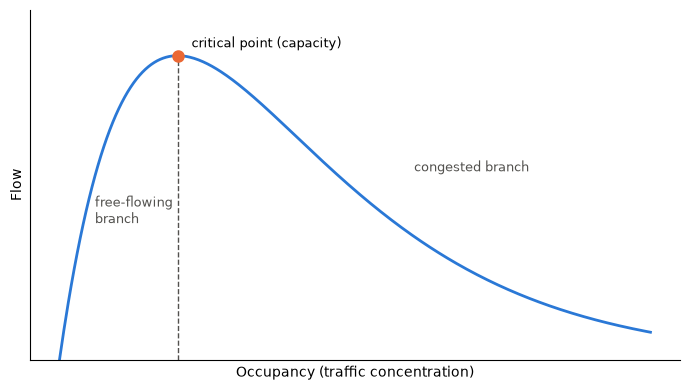

In [ ]:
# Figure 2.1: schematic flow-occupancy curve (theory, no data)
SCHEMATIC_PEAK = 20  # where the schematic peaks; the axes carry no numbers
occupancy = np.linspace(0, 100, 400)
flow = occupancy / SCHEMATIC_PEAK * np.exp(1 - occupancy / SCHEMATIC_PEAK)  # single-peaked, maximum 1 at the peak
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(occupancy, flow, color=COLORS[0], lw=2)
ax.plot([SCHEMATIC_PEAK] * 2, [0, 1], color=INK, lw=1, ls="--")
ax.plot(SCHEMATIC_PEAK, 1, "o", color=COLORS[1], ms=8)
ax.annotate("critical point (capacity)", (SCHEMATIC_PEAK, 1), xytext=(10, 6), textcoords="offset points", fontsize=9)
ax.text(6, 0.45, "free-flowing\nbranch", fontsize=9, color=INK)
ax.text(60, 0.62, "congested branch", fontsize=9, color=INK)
ax.set(xlabel="Occupancy (traffic concentration)", ylabel="Flow", xticks=[], yticks=[], ylim=(0, 1.15))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig-2-1-schematic-curve.png", dpi=200)

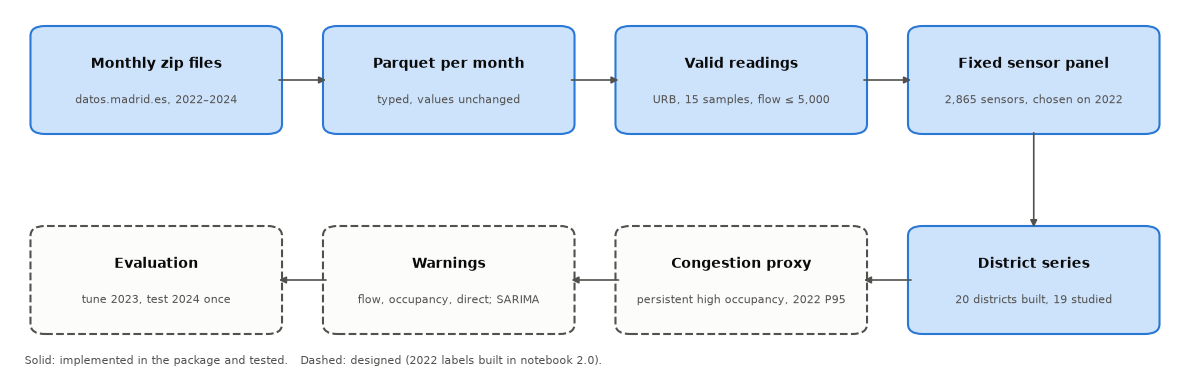

In [ ]:
# Figure 3.1: study pipeline; solid boxes are implemented in the package and tested, dashed boxes are designed
STEPS = [
    ("Monthly zip files", "datos.madrid.es, 2022–2024", True),
    ("Parquet per month", "typed, values unchanged", True),
    ("Valid readings", "URB, 15 samples, flow ≤ 5,000", True),
    ("Fixed sensor panel", "2,865 sensors, chosen on 2022", True),
    ("District series", "20 districts built, 19 studied", True),
    ("Congestion proxy", "persistent high occupancy, 2022 P95", False),
    ("Warnings", "flow, occupancy, direct; SARIMA", False),
    ("Evaluation", "tune 2023, test 2024 once", False),
]
POSITIONS = [(0, 1), (1, 1), (2, 1), (3, 1), (3, 0), (2, 0), (1, 0), (0, 0)]  # right along the top, back along the bottom
BOX_W, BOX_H = 0.82, 0.5
fig, ax = plt.subplots(figsize=(12, 4))
for (title, detail, built), (x, y) in zip(STEPS, POSITIONS):
    ax.add_patch(FancyBboxPatch(
        (x - BOX_W / 2, y - BOX_H / 2), BOX_W, BOX_H, boxstyle="round,pad=0.02,rounding_size=0.05",
        facecolor="#cde2fb" if built else "#fcfcfb", edgecolor=COLORS[0] if built else INK,
        linewidth=1.5, linestyle="-" if built else "--",
    ))
    ax.text(x, y + 0.08, title, ha="center", va="center", fontsize=10, weight="bold", color="#0b0b0b")
    ax.text(x, y - 0.1, detail, ha="center", va="center", fontsize=8, color=INK)
for (x0, y0), (x1, y1) in zip(POSITIONS, POSITIONS[1:]):
    if y0 == y1:  # along a row
        step = np.sign(x1 - x0) * BOX_W / 2
        start, end = (x0 + step, y0), (x1 - step, y1)
    else:  # down to the next row
        start, end = (x0, y0 - BOX_H / 2), (x1, y1 + BOX_H / 2)
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.2))
ax.text(-0.45, -0.42, "Solid: implemented in the package and tested.   Dashed: designed (2022 labels built in notebook 2.0).", fontsize=8, color=INK)
ax.set(xlim=(-0.5, 3.5), ylim=(-0.5, 1.35))
ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig-3-1-pipeline.png", dpi=200)

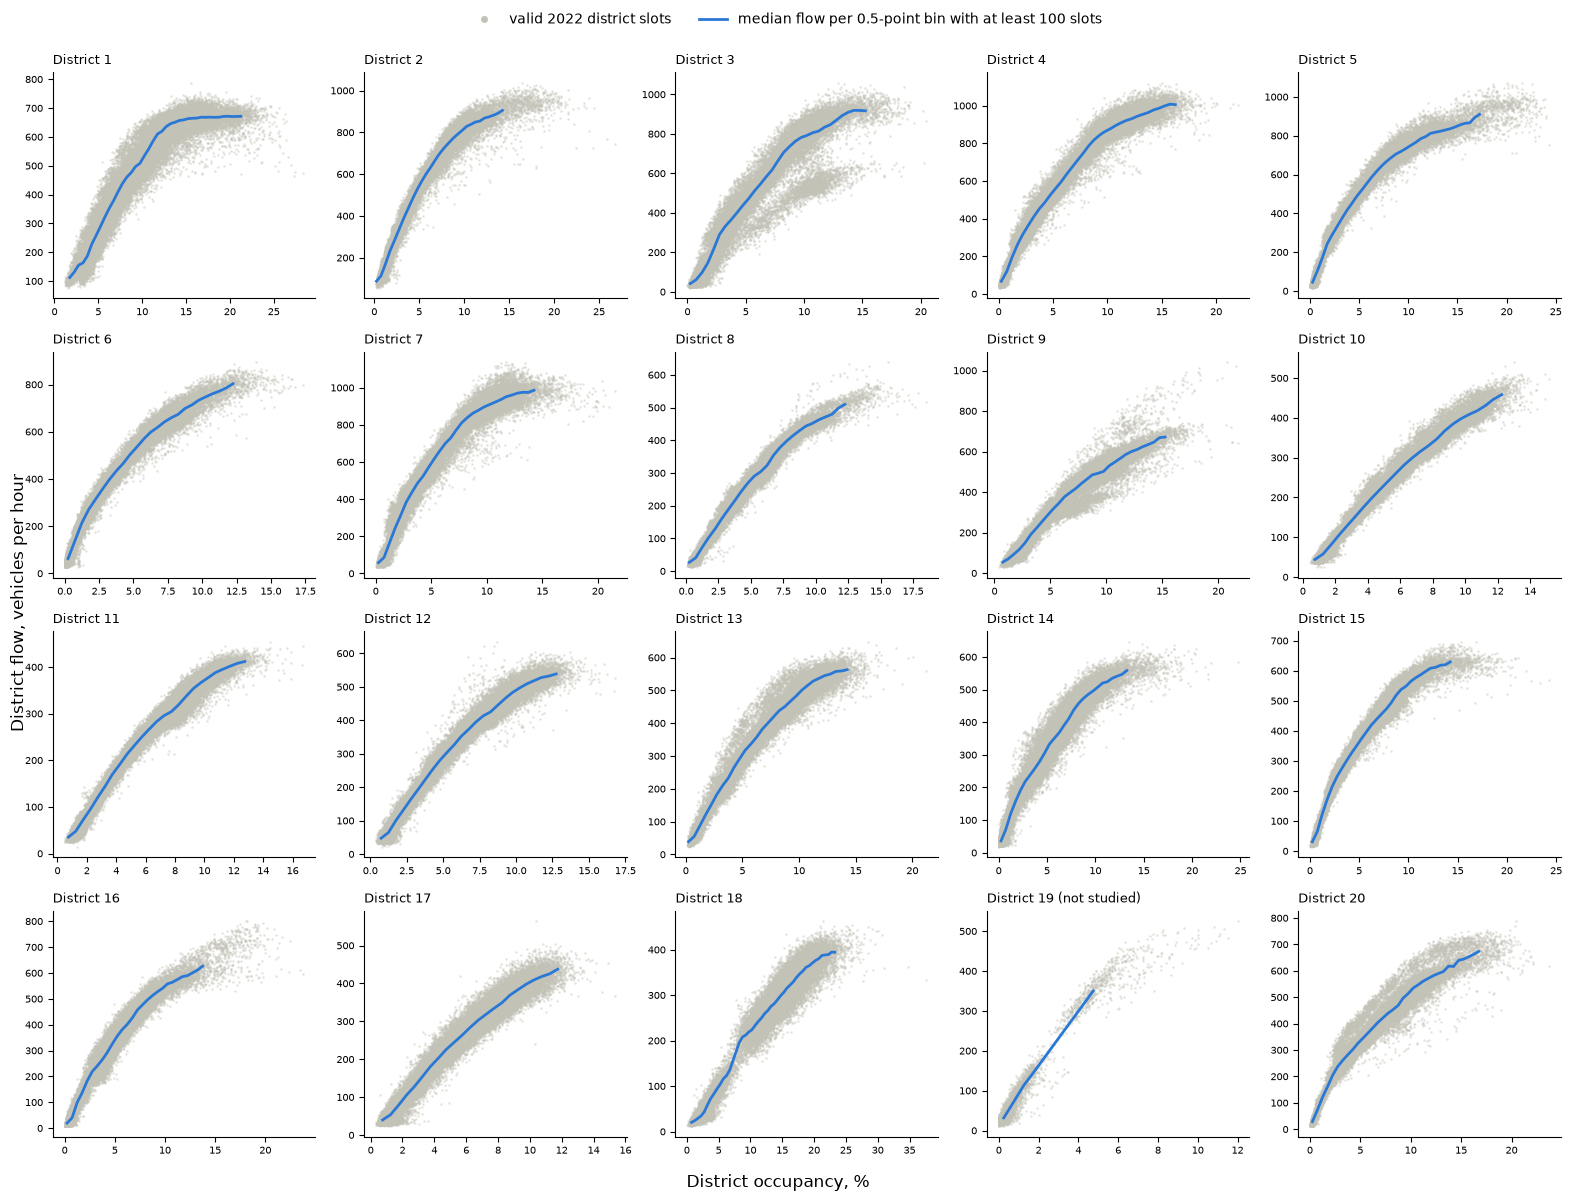

In [ ]:
# Figure 3.5: flow against occupancy per district, 2022 (descriptive; median flow per 0.5-point bin with >= 100 slots)
valid = series.filter(pl.col("valid_slot"))
dense = (
    valid.with_columns(bin_index=(pl.col("occupancy") / BIN_WIDTH).floor().cast(pl.Int32))
    .group_by("distrito", "bin_index").agg(slots=pl.len(), median_flow=pl.col("flow").median())
    .filter(pl.col("slots") >= MIN_BIN_SLOTS).sort("distrito", "bin_index")
)
districts = sorted(series["distrito"].unique().to_list())
fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for ax, district in zip(axes.flat, districts):
    slots = valid.filter(pl.col("distrito") == district)
    bins = dense.filter(pl.col("distrito") == district)
    ax.scatter(slots["occupancy"], slots["flow"], s=1, color=MUTED, alpha=0.3, rasterized=True)
    ax.plot((bins["bin_index"] + 0.5) * BIN_WIDTH, bins["median_flow"], color=COLORS[0], lw=2)
    ax.set_title(f"District {district}" + ("" if district in studied.to_list() else " (not studied)"), loc="left", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(districts):]:
    ax.set_visible(False)
fig.supxlabel("District occupancy, %")
fig.supylabel("District flow, vehicles per hour")
fig.legend(
    [Line2D([], [], color=MUTED, marker="o", ls="", ms=4), Line2D([], [], color=COLORS[0], lw=2)],
    ["valid 2022 district slots", f"median flow per 0.5-point bin with at least {MIN_BIN_SLOTS} slots"],
    loc="upper center", ncol=2, frameon=False,
)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIGURES_DIR / "fig-3-5-curves-2022.png", dpi=200)

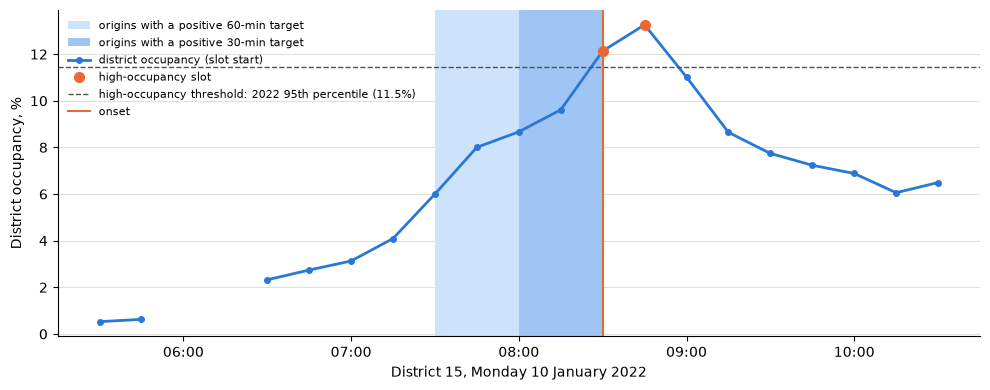

In [ ]:
# Figure 3.6: one example morning under the final label (district 15, the largest studied district).
# The first weekday onset of 2022 between 07:00 and 09:59 whose slots s-7 ... s+4 are all valid
# (what the four 60-min origins s-4 ... s-1 need, from look-back t-3 to the confirming slot t+H+1).
EXAMPLE_DISTRICT = 15
example = labels.filter(pl.col("distrito") == EXAMPLE_DISTRICT)
threshold = references.filter(pl.col("distrito") == EXAMPLE_DISTRICT)["threshold"].item()
candidates = example.filter(pl.col("onset") & (pl.col("slot_start").dt.weekday() <= 5) & pl.col("slot_start").dt.hour().is_between(7, 9))["slot_start"]
onset_time = next(t for t in candidates if example.filter(pl.col("slot_start").is_between(t - 7 * SLOT, t + 4 * SLOT))["valid_slot"].all())
window = example.filter(pl.col("slot_start").is_between(onset_time - 12 * SLOT, onset_time + 8 * SLOT)).with_columns(
    shown=pl.when(pl.col("valid_slot")).then(pl.col("occupancy")),  # invalid slots are not drawn
)
times, occupancy, high = window["slot_start"].to_list(), window["shown"].to_numpy(), window["high"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 4))
for lead, color, label in [(4, "#cde2fb", "origins with a positive 60-min target"), (2, "#9ec5f4", "origins with a positive 30-min target")]:
    for k in range(1, lead + 1):  # calm origins t = onset - k
        ax.axvspan(onset_time - k * SLOT, onset_time - (k - 1) * SLOT, color=color, lw=0, label=label if k == 1 else None)
ax.plot(times, occupancy, color=COLORS[0], lw=2, marker="o", ms=4, label="district occupancy (slot start)")
ax.plot([t for t, h in zip(times, high) if h], occupancy[high], "o", color=COLORS[1], ms=7, label="high-occupancy slot")
ax.axhline(threshold, color=INK, lw=1, ls="--", label=f"high-occupancy threshold: 2022 95th percentile ({threshold:.1f}%)")
ax.axvline(onset_time, color=COLORS[1], lw=1.5, label="onset")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set(xlabel=f"District {EXAMPLE_DISTRICT}, {onset_time:%A %d %B %Y}", ylabel="District occupancy, %")
ax.legend(frameon=False, fontsize=8, loc="upper left")
tidy(ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig-3-6-example-onset.png", dpi=200)